# WEATHER DATA ANALYSIS DASHBOARD

## PART 1: NOTEBOOK STRUCTURE

## 1. Project Introduction

### Project Overview
This project aims to explore weather patterns through
statistical analysis, data visualization and interactive reporting.

#### Project Objectives
- Understand the structure and quality of the dataset.
- Identify patterns in weather conditions.
- Explore relationships between weather variables.
- Communicate findings through visualizations.
- Develop an interactive weather analysis dashboard.

In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

In [66]:
df = pd.read_csv("weather_data.csv")

### Dataset Preview
The first five rows are displayed to understand the structure and contents of the dataset.

In [67]:
display(df.head())

,Formatted Date,Time,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Pressure (millibars),Humidity,Month,Day,Year
0,4/1/2006,00:00:00.000,Partly Cloudy,rain,9.472222,7.388889,14.1197,251.0,15.8263,1015.13,0.89,4,1,2006
1,4/1/2006,01:00:00.000,Partly Cloudy,rain,9.355556,7.227778,14.2646,259.0,15.8263,1015.63,0.86,4,1,2006
2,4/1/2006,02:00:00.000,Mostly Cloudy,rain,9.377778,9.377778,3.9284,204.0,14.9569,1015.94,0.89,4,1,2006
3,4/1/2006,03:00:00.000,Partly Cloudy,rain,8.288889,5.944444,14.1036,269.0,15.8263,1016.41,0.83,4,1,2006
4,4/1/2006,04:00:00.000,Mostly Cloudy,rain,8.755556,6.977778,11.0446,259.0,15.8263,1016.51,0.83,4,1,2006


### Dataset Structure

This section examines the dataset's dimensions, column names, data types and non-null values.

In [68]:
print("Shape:", df.shape)
df.info()
print("Columns:", df.columns.to_list())

Shape: (96453, 14)
<class 'pandas.DataFrame'>
RangeIndex: 96453 entries, 0 to 96452
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Formatted Date            96453 non-null  str    
 1   Time                      96453 non-null  str    
 2   Summary                   96453 non-null  str    
 3   Precip Type               95936 non-null  str    
 4   Temperature (C)           96453 non-null  float64
 5   Apparent Temperature (C)  96453 non-null  float64
 6   Wind Speed (km/h)         96453 non-null  float64
 7   Wind Bearing (degrees)    96453 non-null  float64
 8   Visibility (km)           96453 non-null  float64
 9   Pressure (millibars)      96453 non-null  float64
 10  Humidity                  96453 non-null  float64
 11  Month                     96453 non-null  int64  
 12  Day                       96453 non-null  int64  
 13  Year                      96453 non-null  int64  
dty

### Column Identification
The dataset columns are grouped into categories to understand the available weather information.

In [69]:
column_groups = {
    "Date & Time": ["Formatted Date", "Time", "Month", "Day", "Year"],
    "Weather Conditions": ["Summary", "Precip Type"],
    "Temperature": ["Temperature (C)", "Apparent Temperature (C)"],
    "Wind": ["Wind Speed (km/h)", "Wind Bearing (degrees)"],
    "Atmospheric": ["Visibility (km)", "Pressure (millibars)", "Humidity"]
}

for category, columns in column_groups.items():
    print(f"\n{category}:")
    print(columns)


Date & Time:
['Formatted Date', 'Time', 'Month', 'Day', 'Year']

Weather Conditions:
['Summary', 'Precip Type']

Temperature:
['Temperature (C)', 'Apparent Temperature (C)']

Wind:
['Wind Speed (km/h)', 'Wind Bearing (degrees)']

Atmospheric:
['Visibility (km)', 'Pressure (millibars)', 'Humidity']


### Statistical Summary

Descriptive statistics help us understand the central tendency, spread and range of numerical variables.

In [70]:
df.describe()

,Temperature (C),Apparent Temperature (C),Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Pressure (millibars),Humidity,Month,Day,Year
count,96453.000000,96453.000000,96453.000000,96453.000000,96453.000000,96453.000000,96453.000000,96453.000000,96453.00000,96453.000000
mean,11.932678,10.855029,10.810640,187.509232,10.347325,1003.235956,0.734899,6.523799,15.72708,2011.000404
std,9.551546,10.696847,6.913571,107.383428,4.192123,116.969906,0.195473,3.448495,8.80216,3.162142
min,-21.822222,-27.716667,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.00000,2006.000000
25%,4.688889,2.311111,5.828200,116.000000,8.339800,1011.900000,0.600000,4.000000,8.00000,2008.000000
50%,12.000000,12.000000,9.965900,180.000000,10.046400,1016.450000,0.780000,7.000000,16.00000,2011.000000
75%,18.838889,18.838889,14.135800,290.000000,14.812000,1021.090000,0.890000,10.000000,23.00000,2014.000000
max,39.905556,39.344444,63.852600,359.000000,16.100000,1046.380000,1.000000,12.000000,31.00000,2016.000000


### Observations

- The average temperature is approximately 11.93°C.
- The average apparent temperature is approximately 10.86°C.
- Average wind speed is approximately 10.81 km/h.
- Average humidity is approximately 0.735 (73.5%).
- Temperature ranges from -21.82°C to 39.91°C.
- Wind speed ranges from 0 to 63.85 km/h.
- The dataset covers observations from 2006 to 2016.

These statistics provide an initial understanding of the weather variables and their distributions.

### Research Questions

| No. | Type | Research Question | Column(s) |
|---:|---|---|---|
| 1 | Univariate | How is temperature distributed across the observations? | `Temperature (C)` |
| 2 | Univariate | How does humidity vary across the observations? | `Humidity` |
| 3 | Univariate | Which weather conditions occur most frequently? | `Summary` |
| 4 | Bivariate | Is there a relationship between temperature and humidity? | `Temperature (C)`, `Humidity` |
| 5 | Bivariate | How closely does apparent temperature relate to actual temperature? | `Temperature (C)`, `Apparent Temperature (C)` |

## Part 2 — Analysis in Notebook

### Step 1: Basic Analysis


#### Date Conversion
Convert the date column into datetime format to identify the dataset's date range.


In [71]:
df["Formatted Date"] = pd.to_datetime(df["Formatted Date"], format= "%m/%d/%Y")

print("First Date:", df["Formatted Date"].min())
print("Last Date:", df["Formatted Date"].max())

First Date: 2006-01-01 00:00:00
Last Date: 2016-12-31 00:00:00


The dataset contains weather observations from January 1, 2006, to December 31, 2016, covering a period of 11 years.

### Step 2: Missing Values
This section checks whether any columns contain missing values.

In [72]:
df.isnull().sum()

Formatted Date                0
Time                          0
Summary                       0
Precip Type                 517
Temperature (C)               0
Apparent Temperature (C)      0
Wind Speed (km/h)             0
Wind Bearing (degrees)        0
Visibility (km)               0
Pressure (millibars)          0
Humidity                      0
Month                         0
Day                           0
Year                          0
dtype: int64

The dataset contains 517 missing values in the Precip Type column. All other columns are complete.

In [73]:
df["Precip Type"].value_counts(dropna=False)

Precip Type
rain    85224
snow    10712
NaN       517
Name: count, dtype: int64

Rain is the most frequent precipitation type, with 85,224 records, followed by snow with 10,712 records. There are 517 missing entries, representing approximately 0.54% of the dataset.

In [74]:
df.loc[df["Precip Type"].isna(), "Summary"].value_counts()

Summary
Mostly Cloudy    180
Clear            127
Partly Cloudy     98
Overcast          81
Foggy             31
Name: count, dtype: int64

The missing precipitation types occur alongside different weather summaries. We cannot safely assume they mean rain or snow.

### Step 3: Duplicate Records
This step identifies duplicate records to avoid counting the same observation more than once.

In [75]:
print("Total Duplicate Rows:", df.duplicated().sum())
df[df.duplicated()]

Total Duplicate Rows: 24


,Formatted Date,Time,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Pressure (millibars),Humidity,Month,Day,Year
36072,2010-08-02,00:00:00.000,Clear,rain,18.800000,18.800000,6.2790,270.0,14.9086,1016.99,0.93,8,2,2010
36073,2010-08-02,01:00:00.000,Clear,rain,18.222222,18.222222,6.2790,291.0,14.9086,1017.09,0.97,8,2,2010
36074,2010-08-02,02:00:00.000,Clear,rain,18.072222,18.072222,11.2700,290.0,6.8425,1013.23,0.98,8,2,2010
36075,2010-08-02,03:00:00.000,Clear,rain,16.622222,16.622222,6.4400,300.0,11.9784,1016.78,0.99,8,2,2010
36076,2010-08-02,04:00:00.000,Clear,rain,16.094444,16.094444,3.0751,280.0,11.9784,1016.67,0.99,8,2,2010
36077,2010-08-02,05:00:00.000,Clear,rain,15.955556,15.955556,3.8801,276.0,9.9820,1016.69,0.99,8,2,2010
36078,2010-08-02,06:00:00.000,Clear,rain,17.088889,17.088889,6.4400,310.0,9.9820,1017.08,1.00,8,2,2010
36079,2010-08-02,07:00:00.000,Clear,rain,20.822222,20.822222,3.2200,300.0,9.9820,1017.27,0.87,8,2,2010
36080,2010-08-02,08:00:00.000,Clear,rain,23.405556,23.405556,1.8837,334.0,9.9820,1017.27,0.74,8,2,2010
36081,2010-08-02,09:00:00.000,Clear,rain,26.050000,26.050000,1.5939,5.0,9.9820,1017.15,0.59,8,2,2010


In [76]:
df[df.duplicated(keep=False)]

,Formatted Date,Time,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Pressure (millibars),Humidity,Month,Day,Year
8040,2010-08-02,00:00:00.000,Clear,rain,18.800000,18.800000,6.2790,270.0,14.9086,1016.99,0.93,8,2,2010
8041,2010-08-02,01:00:00.000,Clear,rain,18.222222,18.222222,6.2790,291.0,14.9086,1017.09,0.97,8,2,2010
8042,2010-08-02,02:00:00.000,Clear,rain,18.072222,18.072222,11.2700,290.0,6.8425,1013.23,0.98,8,2,2010
8043,2010-08-02,03:00:00.000,Clear,rain,16.622222,16.622222,6.4400,300.0,11.9784,1016.78,0.99,8,2,2010
8044,2010-08-02,04:00:00.000,Clear,rain,16.094444,16.094444,3.0751,280.0,11.9784,1016.67,0.99,8,2,2010
8045,2010-08-02,05:00:00.000,Clear,rain,15.955556,15.955556,3.8801,276.0,9.9820,1016.69,0.99,8,2,2010
8046,2010-08-02,06:00:00.000,Clear,rain,17.088889,17.088889,6.4400,310.0,9.9820,1017.08,1.00,8,2,2010
8047,2010-08-02,07:00:00.000,Clear,rain,20.822222,20.822222,3.2200,300.0,9.9820,1017.27,0.87,8,2,2010
8048,2010-08-02,08:00:00.000,Clear,rain,23.405556,23.405556,1.8837,334.0,9.9820,1017.27,0.74,8,2,2010
8049,2010-08-02,09:00:00.000,Clear,rain,26.050000,26.050000,1.5939,5.0,9.9820,1017.15,0.59,8,2,2010


Remove exact duplicates.

Since they add no new information, we can safely remove the repeated copies.

In [77]:
df = df.drop_duplicates()

print("Remaining Duplicate Rows:", df.duplicated().sum())
print("Updated Dataset Shape", df.shape)

Remaining Duplicate Rows: 0
Updated Dataset Shape (96429, 14)


Observation
The dataset initially contained 96,453 rows. After removing 24 exact duplicates, it contains 96,429 rows and 14 columns. No duplicate rows remain.

In [78]:
df.duplicated(subset=["Formatted Date", "Time"]).sum()

np.int64(11)

In [79]:
df[df.duplicated(subset=["Formatted Date", "Time"], keep=False)]

,Formatted Date,Time,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Pressure (millibars),Humidity,Month,Day,Year
7801,2006-10-29,02:00:00.000,Partly Cloudy,rain,11.327778,11.327778,27.9818,308.0,14.5866,1010.75,0.78,10,29,2006
7802,2006-10-29,02:00:00.000,Foggy,rain,9.050000,9.050000,3.7835,236.0,2.0286,1020.60,0.96,10,29,2006
16561,2007-10-28,02:00:00.000,Overcast,rain,9.777778,9.777778,2.9624,152.0,4.2665,1022.38,0.96,10,28,2007
16562,2007-10-28,02:00:00.000,Foggy,rain,7.777778,7.777778,0.0000,0.0,0.1610,0.00,0.96,10,28,2007
25297,2008-10-26,02:00:00.000,Mostly Cloudy,rain,8.150000,8.150000,3.8801,157.0,6.1663,1025.71,0.84,10,26,2008
25298,2008-10-26,02:00:00.000,Partly Cloudy,rain,7.800000,6.788889,6.6010,272.0,6.0697,1031.90,0.86,10,26,2008
34033,2009-10-25,02:00:00.000,Foggy,rain,12.172222,12.172222,6.2307,308.0,2.7853,1020.20,0.93,10,25,2009
34034,2009-10-25,02:00:00.000,Mostly Cloudy,rain,11.111111,11.111111,6.4400,330.0,8.0500,1016.60,0.93,10,25,2009
42961,2010-10-31,02:00:00.000,Clear,rain,4.111111,1.655556,9.8371,145.0,9.9820,1018.46,0.83,10,31,2010
42962,2010-10-31,02:00:00.000,Partly Cloudy,rain,2.177778,0.400000,6.2629,169.0,6.9874,1019.45,0.83,10,31,2010


The dataset contains 11 repeated date-time combinations. These occur at 02:00 AM on October dates across different years. Since the weather values differ, these are not exact duplicate records and are retained. The dataset does not include timezone information, so the exact cause of these repeated timestamps cannot be confirmed.

### Step 4: Outlier Detection
#### Temperature Outliers

We will use box plots and the IQR method to identify and investigate potential temperature outliers.

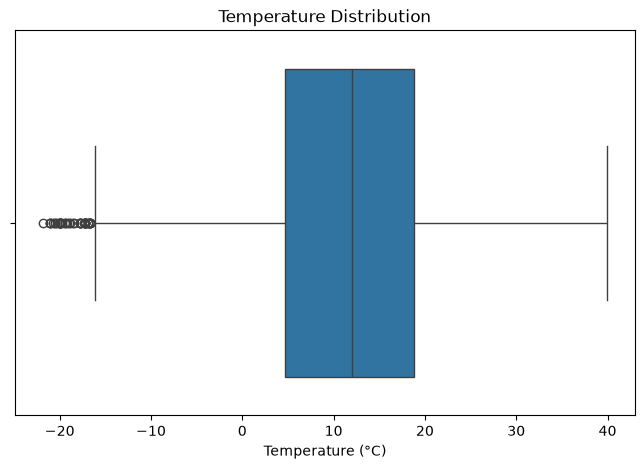

In [80]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=df["Temperature (C)"])
plt.title("Temperature Distribution")
plt.xlabel("Temperature (°C)")
plt.show()

The box plot shows how temperature is distributed.

- **Q1 (≈ 5°C):** 25% of temperatures are below this.
- **Median (≈ 12°C):** The middle value.
- **Q3 (≈ 19°C):** 75% of temperatures are below this.
- **Whiskers:** Extend to the furthest observations within the 1.5 × IQR limits.
- **Outliers:** Values beyond the whiskers, shown as individual points.

**Observation:** Most temperatures fall between 5°C and 19°C, with a few unusually low values.

The Interquartile Range (IQR) measures the spread of the middle 50% of data. It helps identify potential outliers.

**Formulas:**
- IQR = Q3 − Q1
- Lower Limit = Q1 − (1.5 × IQR)
- Upper Limit = Q3 + (1.5 × IQR)

In [81]:
Q1 = df["Temperature (C)"].quantile(0.25)
Q3 = df["Temperature (C)"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - (1.5 * IQR)
upper_limit = Q3 + (1.5 * IQR)

print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)


IQR: 14.155555557
Lower Limit: -16.5500000025
Upper Limit: 40.0722222255


- **IQR (14.16°C):** The middle 50% of temperatures span approximately 14.16°C.
- **Lower Limit (-16.55°C):** Values below this are potential outliers.
- **Upper Limit (40.07°C):** Values above this are potential outliers.

**Observation:** Values outside these limits are potential statistical outliers and require further investigation.

##### Identify Temperature Outliers
This step identifies temperature values that fall outside the calculated IQR limits.

In [82]:
temp_outliers = df[
    (df["Temperature (C)"] < lower_limit) |
    (df["Temperature (C)"] > upper_limit)
]

print("Number of temperature outliers:", len(temp_outliers))
temp_outliers["Temperature (C)"].describe()

Number of temperature outliers: 44


count    44.000000
mean    -18.652652
std       1.581676
min     -21.822222
25%     -20.000000
50%     -18.458333
75%     -17.222222
max     -16.666667
Name: Temperature (C), dtype: float64

The IQR method identified 44 potential temperature outliers.

Mean (-18.65°C): Average temperature of the outliers.

Minimum (-21.82°C): Lowest recorded temperature.

Maximum (-16.67°C): Highest recorded temperature among the outliers.

Median (-18.46°C): Middle value of the outlier temperatures.

Observation: All 44 values fall below the lower limit of -16.55°C.

We will examine the dates and times of the identified outliers to investigate when these extreme temperatures occurred.

In [83]:
temp_outliers[["Formatted Date", "Time", "Temperature (C)"]].sort_values("Temperature (C)")

,Formatted Date,Time,Temperature (C)
54847,2012-02-10,07:00:00.000,-21.822222
55493,2012-02-09,05:00:00.000,-21.111111
55494,2012-02-09,06:00:00.000,-21.111111
55490,2012-02-09,02:00:00.000,-21.111111
55495,2012-02-09,07:00:00.000,-20.783333
54866,2012-02-11,02:00:00.000,-20.555556
55491,2012-02-09,03:00:00.000,-20.555556
55492,2012-02-09,04:00:00.000,-20.277778
55489,2012-02-09,01:00:00.000,-20.050000
55487,2012-02-08,23:00:00.000,-20.000000


Most temperature outliers occurred between February 8 and 11, 2012. Several readings were recorded in consecutive hours, showing a consistent period of extremely cold weather.

These values may represent genuine weather extremes rather than data errors. Therefore, they are retained for further analysis.

##### Wind Speed 
Now we calculate the IQR limits for wind speed to identify potential outliers.

In [84]:
Q1_wind = df["Wind Speed (km/h)"].quantile(0.25)
Q3_wind = df["Wind Speed (km/h)"].quantile(0.75)

IQR_wind = Q3_wind - Q1_wind 

lower_wind = Q1_wind - (1.5 * IQR_wind)
upper_wind = Q3_wind + (1.5 * IQR_wind)

print("IQR:", IQR_wind)
print("Lower Limit:", lower_wind)
print("Upper Limit:", upper_wind)

IQR: 8.3076
Lower Limit: -6.633200000000001
Upper Limit: 26.5972


- IQR (8.31 km/h): The middle 50% of wind speeds span approximately 8.31 km/h.
- Lower Limit (-6.63 km/h): Values below this are potential outliers. Since wind speed cannot be negative, no lower outliers are possible.
- Upper Limit (26.60 km/h): Values above this are potential outliers.

Observation: Wind speeds above 26.60 km/h are potential statistical outliers and need further investigation.

In [85]:
wind_outliers = df[df["Wind Speed (km/h)"] > upper_wind]

print("Number of wind speed outliers:", len(wind_outliers))
wind_outliers["Wind Speed (km/h)"].describe()

Number of wind speed outliers: 3020


count    3020.000000
mean       31.509193
std         4.537339
min        26.613300
25%        27.933500
50%        30.308250
75%        33.810000
max        63.852600
Name: Wind Speed (km/h), dtype: float64

Wind Speed Outlier Results
- Count (3,020): Number of observations above the upper limit.
- Mean (31.51 km/h): Average wind speed among these outliers.
- Minimum (26.61 km/h): Lowest outlier value.
- Maximum (63.85 km/h): Highest recorded wind speed among them.
- Median (30.31 km/h): Middle value of the outlier wind speeds.

Observation: All 3,020 values exceed the upper limit of 26.60 km/h. The highest reaches 63.85 km/h.

Let's check when these high wind speeds occurred:

In [86]:
wind_outliers[["Formatted Date", "Time", "Wind Speed (km/h)"]].sort_values("Wind Speed (km/h)", ascending=False)


,Formatted Date,Time,Wind Speed (km/h)
12181,2007-01-29,13:00:00.000,63.8526
20927,2008-01-27,23:00:00.000,55.9314
75398,2014-03-15,17:00:00.000,54.8849
12182,2007-01-29,14:00:00.000,53.5969
12179,2007-01-29,11:00:00.000,53.2427
...,...,...,...
72354,2014-12-09,18:00:00.000,26.6133
26411,2009-04-12,11:00:00.000,26.6133
76590,2014-05-04,10:00:00.000,26.6133
16044,2007-11-08,13:00:00.000,26.6133


The IQR method identified 3,020 potential wind speed outliers.

The highest recorded wind speed is 63.85 km/h. Several high readings occurred close together in time, while others appeared across different dates and years.

These values may represent genuine periods of strong wind rather than recording errors. Therefore, they are retained for further analysis.

##### Wind Speed Distribution — Histogram
A histogram shows how frequently different wind speed ranges occur. It helps us understand the overall distribution and spread.

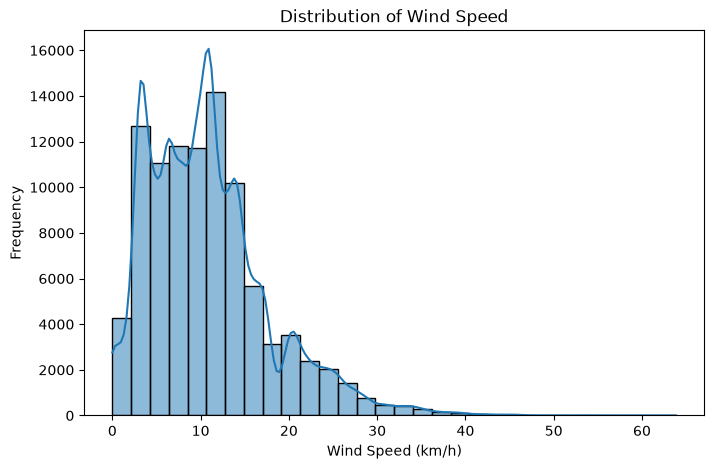

In [87]:
plt.figure(figsize=(8, 5))
sns.histplot(df["Wind Speed (km/h)"], bins=30, kde=True)

plt.title("Distribution of Wind Speed")
plt.xlabel("Wind Speed (km/h)")
plt.ylabel("Frequency")
plt.show()

The histogram shows that wind speed is right-skewed.

- Most observations fall between 0 and 20 km/h.
- The highest frequency occurs around 11–12 km/h.
- Frequencies decrease as wind speed increases.
- Wind speeds above 40 km/h are relatively rare.

**Observation:** Wind speeds are generally low, while very high wind speeds occur much less frequently.

##### Wind Speed — Box Plot
A box plot helps us visualize the median, spread, and potential outliers in wind speed.

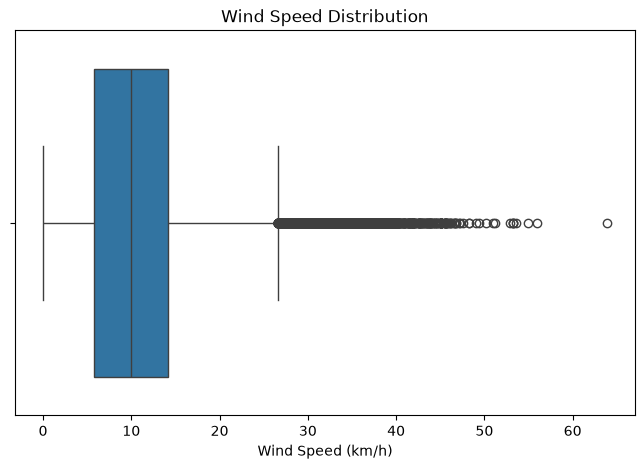

In [88]:
plt.figure(figsize=(8,5))
sns.boxplot(x=df["Wind Speed (km/h)"])

plt.title("Wind Speed Distribution")
plt.xlabel("Wind Speed (km/h)")
plt.show()

In [89]:
Q1 = df["Wind Speed (km/h)"].quantile(0.25)
Q2 = df["Wind Speed (km/h)"].quantile(0.50)
Q3 = df["Wind Speed (km/h)"].quantile(0.75)

print("Q1:", Q1)
print("Q2:", Q2)
print("Q3:", Q3)

Q1: 5.8282
Q2: 9.9659
Q3: 14.1358


The exact quartile values show that:

- **Q1 (5.83 km/h):** 25% of observations fall below this value.
- **Median (9.97 km/h):** Half of the observations fall below this value.
- **Q3 (14.14 km/h):** 75% of observations fall below this value.

**Observation:** The middle 50% of wind speeds range from approximately 5.83 to 14.14 km/h.

##### IQR for Humidity

In [90]:
Q1_humidity = df["Humidity"].quantile(0.25)
Q3_humidity = df["Humidity"].quantile(0.75)

IQR_humidity = Q3_humidity - Q1_humidity

lower_humidity = Q1_humidity - (1.5 * IQR_humidity)
upper_humidity = Q3_humidity + (1.5 * IQR_humidity)

print("IQR:", IQR_humidity)
print("Lower Limit:", lower_humidity)
print("Upper Limit:", upper_humidity)

IQR: 0.29000000000000004
Lower Limit: 0.16499999999999992
Upper Limit: 1.3250000000000002


In [91]:
humidity_outliers= df[df["Humidity"] < lower_humidity]

print("Number of Humidity Outliers:", len(humidity_outliers))
humidity_outliers["Humidity"].describe()

Number of Humidity Outliers: 46


count    46.000000
mean      0.078043
std       0.075913
min       0.000000
25%       0.000000
50%       0.125000
75%       0.150000
max       0.160000
Name: Humidity, dtype: float64

The IQR method identified 46 potential humidity outliers.
- Mean (0.078): Average humidity among the outliers is approximately 7.8%.
- Minimum (0.000): Lowest recorded humidity is 0%.
- Maximum (0.160): Highest outlier humidity is 16%.
- Median (0.125): Middle value is 12.5%.

Observation: All 46 values fall below the lower limit of 0.165. These unusually low humidity readings require further investigation before deciding whether to retain or remove them.

In [92]:
humidity_outliers[["Formatted Date", "Time", "Humidity"]].sort_values("Humidity")

,Formatted Date,Time,Humidity
54870,2012-02-11,06:00:00.000,0.00
55352,2012-02-03,08:00:00.000,0.00
55349,2012-02-03,05:00:00.000,0.00
55350,2012-02-03,06:00:00.000,0.00
55086,2012-02-02,06:00:00.000,0.00
54873,2012-02-11,09:00:00.000,0.00
54872,2012-02-11,08:00:00.000,0.00
55088,2012-02-02,08:00:00.000,0.00
28110,2009-12-21,06:00:00.000,0.00
54858,2012-02-10,18:00:00.000,0.00


In [93]:
humidity_outliers[
    ["Formatted Date", "Time", "Humidity", "Temperature (C)",
     "Apparent Temperature (C)", "Summary", "Precip Type"]
].sort_values(["Formatted Date", "Time"])

,Formatted Date,Time,Humidity,Temperature (C),Apparent Temperature (C),Summary,Precip Type
9160,2007-04-23,16:00:00.000,0.15,21.205556,21.205556,Dry and Partly Cloudy,rain
9161,2007-04-23,17:00:00.000,0.15,21.244444,21.244444,Dry and Partly Cloudy,rain
12615,2007-07-17,15:00:00.000,0.14,37.777778,35.388889,Clear,rain
12616,2007-07-17,16:00:00.000,0.15,37.822222,35.561111,Clear,rain
12711,2007-07-20,15:00:00.000,0.14,38.983333,36.627778,Partly Cloudy,rain
12712,2007-07-20,16:00:00.000,0.15,38.983333,36.800000,Partly Cloudy,rain
12713,2007-07-20,17:00:00.000,0.14,38.788889,36.477778,Partly Cloudy,rain
12714,2007-07-20,18:00:00.000,0.16,37.894444,35.761111,Dry,rain
12737,2007-07-21,17:00:00.000,0.15,39.588889,37.600000,Partly Cloudy,rain
12738,2007-07-21,18:00:00.000,0.16,37.800000,35.672222,Dry and Partly Cloudy,rain


The 46 potential humidity outliers were examined alongside temperature, apparent temperature, weather summary and precipitation type.

- Several low humidity readings occurred during hot weather in July 2007.
- Multiple 0% readings occurred during cold weather in February 2012 and December 2009.
- Some readings appeared across consecutive hours.

These values may represent genuine weather conditions, but their accuracy cannot be confirmed from the available columns. Therefore, they are retained without modification.

##### Outlier Detection — Rainfall Limitation
**Rainfall limitation:** The dataset does not contain a numerical rainfall amount column. `Precip Type` only identifies whether precipitation is rain or snow, so rainfall distribution and IQR analysis cannot be performed.

### Step 5: Univariate Analysis


#### Q1. How is temperature distributed across the observations?
#### Temperature Distribution — Histogram

A histogram shows the frequency distribution of temperature values and helps identify the most common temperature ranges.

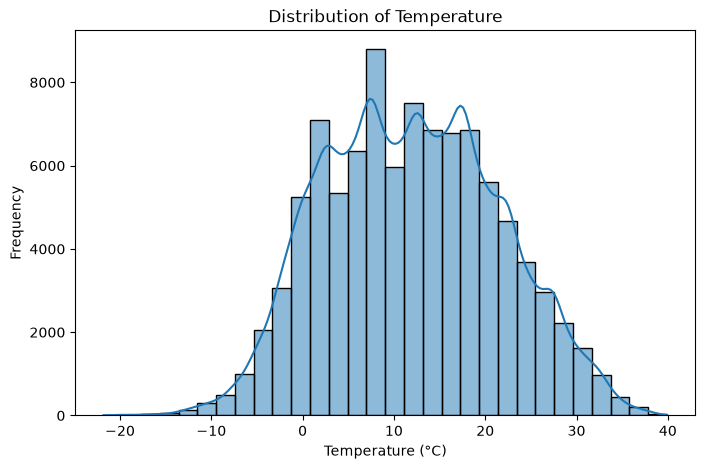

In [94]:
plt.figure(figsize=(8, 5))
sns.histplot(df["Temperature (C)"], bins=30, kde=True)

plt.title("Distribution of Temperature")
plt.xlabel("Temperature (°C)")
plt.ylabel("Frequency")
plt.show()

The histogram shows the frequency distribution of temperature.

- The highest frequency occurs around 7–9°C.
- Most temperatures fall between 0°C and 20°C.
- Very low and very high temperatures occur less frequently.
- The distribution has several peaks rather than one clear peak.

**Observation:** Temperatures are mostly concentrated in the mild range, with fewer observations at extreme temperatures.

#### Q2. How does humidity vary across the observations?

##### Humidity Distribution — Histogram
A histogram shows the frequency distribution of humidity values and helps identify the most common humidity ranges.

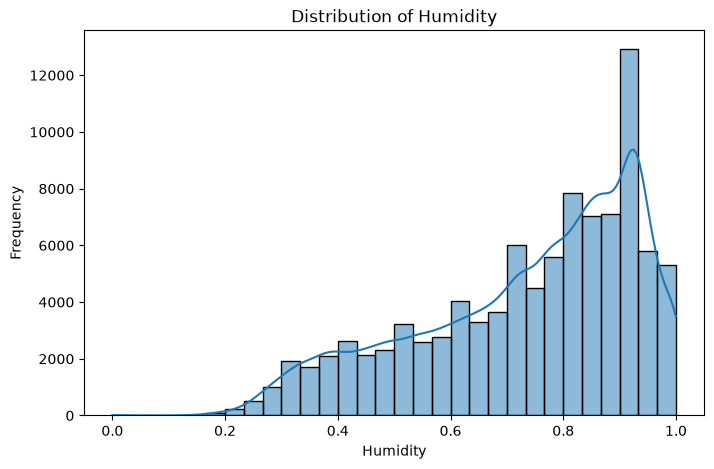

In [95]:
plt.figure(figsize=(8, 5))
sns.histplot(df["Humidity"], bins=30, kde=True)

plt.title("Distribution of Humidity")
plt.xlabel("Humidity")
plt.ylabel("Frequency")
plt.show()

The histogram shows the frequency distribution of humidity.

- The highest frequency occurs around 0.91–0.94.
- Most humidity values fall between 0.7 and 1.0.
- Lower humidity values occur less frequently.
- The distribution is left-skewed, with a longer tail towards lower humidity values.

**Observation:** The dataset contains more observations with high humidity than low humidity.

##### Humidity Distribution — Box Plot
A box plot helps examine the spread of humidity values and identify potential outliers.

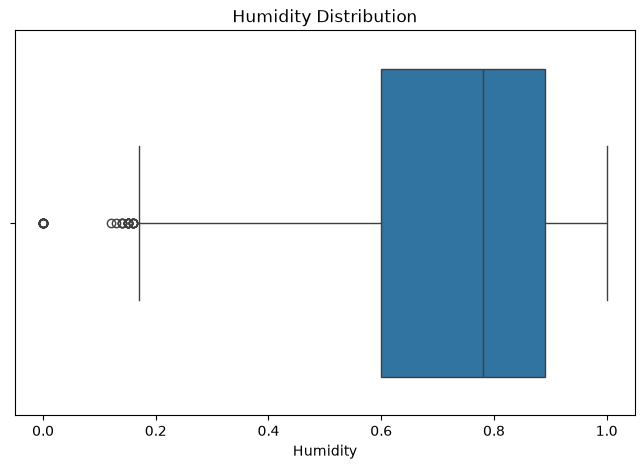

In [96]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=df["Humidity"])

plt.title("Humidity Distribution")
plt.xlabel("Humidity")
plt.show()

In [97]:
Q1 = df["Humidity"].quantile(0.25)
Q2 = df["Humidity"].quantile(0.50)
Q3 = df["Humidity"].quantile(0.75)

print("Q1:", Q1)
print("Median:", Q2)
print("Q3:", Q3)

Q1: 0.6
Median: 0.78
Q3: 0.89


The exact quartile values show that:

- **Q1 (0.60):** 25% of observations fall below this value.
- **Median (0.78):** Half of the observations fall below this value.
- **Q3 (0.89):** 75% of observations fall below this value.

**Observation:** The middle 50% of humidity values range from 60% to 89%.

#### Q3. Which weather conditions occur most frequently?

In [98]:
df["Summary"].value_counts()

Summary
Partly Cloudy                          31726
Mostly Cloudy                          28094
Overcast                               16597
Clear                                  10873
Foggy                                   7148
Breezy and Overcast                      528
Breezy and Mostly Cloudy                 516
Breezy and Partly Cloudy                 386
Dry and Partly Cloudy                     86
Windy and Partly Cloudy                   67
Light Rain                                63
Breezy                                    54
Windy and Overcast                        45
Humid and Mostly Cloudy                   40
Drizzle                                   39
Breezy and Foggy                          35
Windy and Mostly Cloudy                   35
Dry                                       34
Humid and Partly Cloudy                   17
Dry and Mostly Cloudy                     14
Rain                                      10
Windy                                      8
Hu

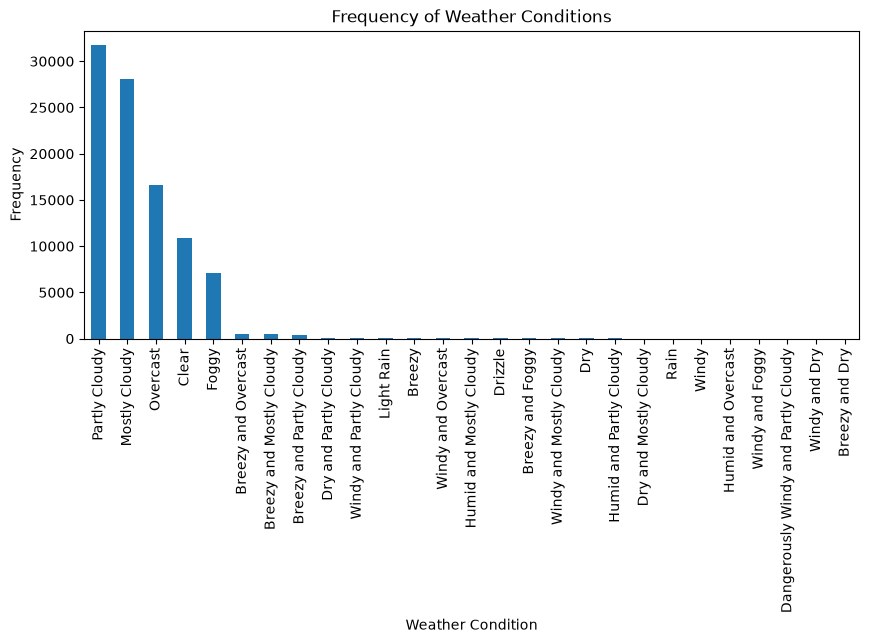

In [99]:
plt.figure(figsize=(10, 4))

df["Summary"].value_counts().plot(kind="bar")

plt.title("Frequency of Weather Conditions")
plt.xlabel("Weather Condition")
plt.ylabel("Frequency")
plt.xticks(rotation=90)
plt.show()

Partly Cloudy is the most frequent weather condition, with 31,726 observations, followed by Mostly Cloudy (28,094) and Overcast (16,597). Clear and Foggy conditions are also relatively common, while the remaining weather conditions have much lower frequencies.

**Observation:** The dataset is dominated by cloudy weather conditions, indicating that cloudy and partly cloudy skies were recorded more frequently than other weather conditions.

#### Step 6: Bivariate Analysis
#### Q4. Is there a relationship between temperature and humidity?

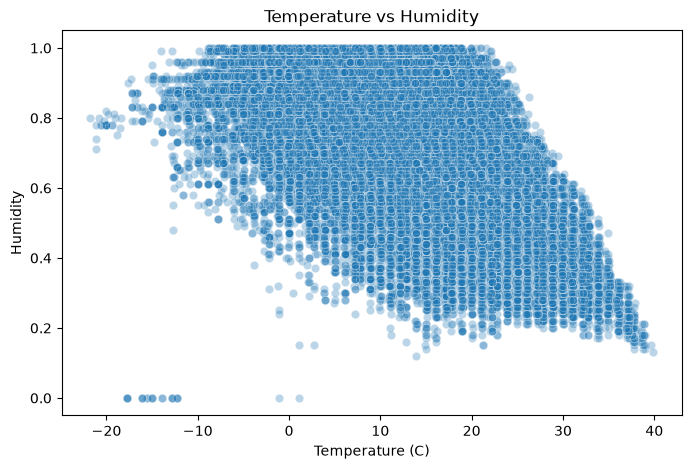

In [100]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df, 
    x="Temperature (C)",
    y = "Humidity",
    alpha=0.3
)

plt.title("Temperature vs Humidity")
plt.xlabel("Temperature (C)")
plt.ylabel("Humidity")
plt.show()

The scatter plot shows a generally negative relationship between temperature and humidity.

- Humidity tends to decrease as temperature increases.
- The points are widely scattered, showing some variation.

**Observation:** Temperature and humidity generally move in opposite directions, indicating a negative association.

In [101]:
correlation = df["Temperature (C)"].corr(df["Humidity"])
print("Correlation Coefficient:", correlation)

Correlation Coefficient: -0.6323310338495959


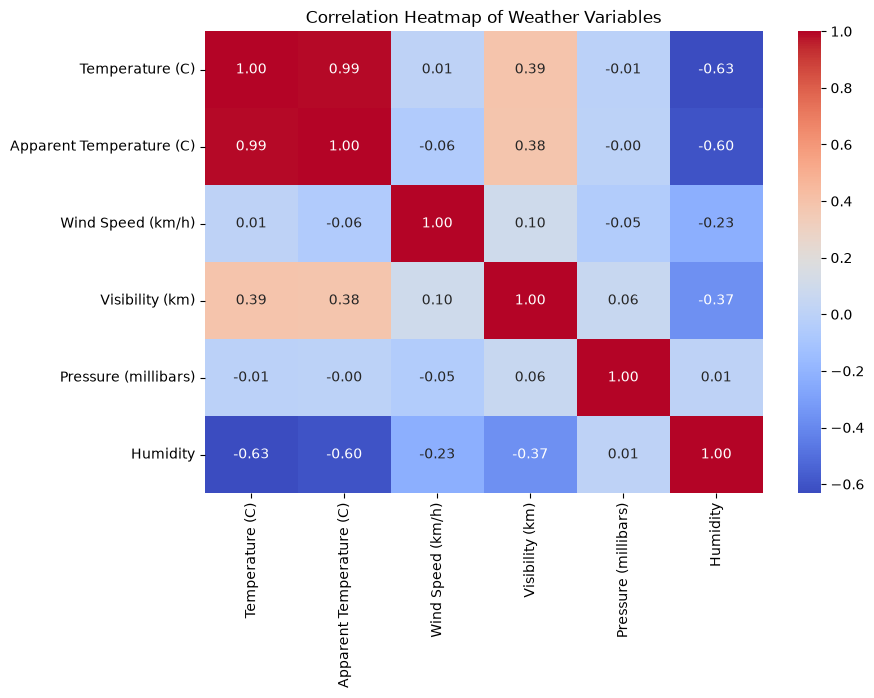

In [102]:
weather_corr = df[[    "Temperature (C)", "Apparent Temperature (C)",
     "Wind Speed (km/h)", "Visibility (km)",
     "Pressure (millibars)", "Humidity"
]].corr()

plt.figure(figsize=(9, 6))
sns.heatmap(weather_corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Weather Variables")
plt.show()

The heatmap shows the relationships between different weather variables.

- Temperature and apparent temperature have a very strong positive correlation (0.99).
- Temperature and humidity show a moderately strong negative correlation (-0.63).
- Visibility and humidity have a negative correlation (-0.37).
- Pressure shows almost no correlation with the other variables.

**Observation:** Temperature and apparent temperature are strongly related, while temperature and humidity tend to move in opposite directions.

#### Q5. How closely does apparent temperature relate to actual temperature?

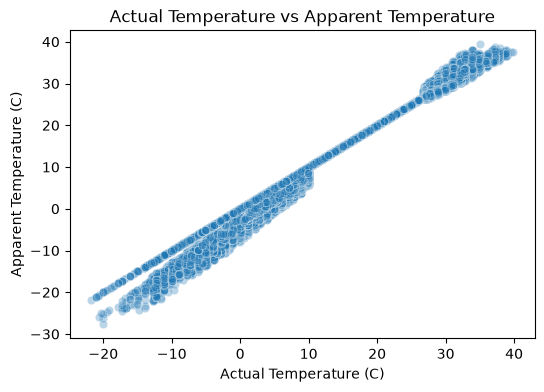

In [103]:
plt.figure(figsize=(6, 4))

sns.scatterplot(
    data=df, 
    x="Temperature (C)",
    y= "Apparent Temperature (C)",
    alpha=0.3
)

plt.title("Actual Temperature vs Apparent Temperature")
plt.xlabel("Actual Temperature (C)")
plt.ylabel("Apparent Temperature (C)")
plt.show()

The scatter plot shows a very strong positive relationship between actual and apparent temperature.

- Apparent temperature generally increases as actual temperature increases.
- Most observations are closely aligned, indicating a strong relationship.

**Observation:** Actual and apparent temperatures move very closely together, showing that they are strongly related.

In [104]:
correlation = df["Temperature (C)"].corr(df["Apparent Temperature (C)"])
print("Correlation Coefficient:", correlation)

Correlation Coefficient: 0.9926254234650589


The correlation coefficient is 0.9926, indicating an almost perfect positive relationship between actual and apparent temperature.

**Observation:** Apparent temperature closely follows actual temperature, showing a very strong relationship between the two variables.

## Step 7: Answers to Research Questions

#### Q1: Temperature Distribution

The temperature distribution shows that most observations fall between 0°C and 20°C, with the highest frequency around 7°C to 9°C. The distribution also contains observations at both lower and higher temperatures.

**Observation:** Most recorded temperatures are concentrated within the 0°C to 20°C range.


#### Q2. Humidity Variation

The humidity distribution shows that most observations fall between 0.7 and 1.0, with the highest frequency around 0.91 to 0.94. The box plot indicates that the middle 50% of humidity values lie between 0.60 and 0.89, with a median of 0.78.

**Observation:** Humidity levels are generally high across the observations.


#### Q3. Frequency of Weather Conditions

Partly Cloudy is the most frequently recorded weather condition, with 31,726 observations, followed by Mostly Cloudy (28,094) and Overcast (16,597). Clear and Foggy conditions are also relatively common, while other weather conditions occur much less frequently.

**Observation:** Cloudy and partly cloudy conditions dominate the dataset.


#### Q4. Relationship Between Temperature and Humidity

The scatter plot shows a generally negative relationship between temperature and humidity. As temperature increases, humidity tends to decrease, although the observations are widely scattered.

The correlation coefficient is approximately **-0.6323**, indicating a moderately strong negative correlation.

**Observation:** Temperature and humidity generally move in opposite directions.


#### Q5. Relationship Between Actual and Apparent Temperature


The scatter plot shows a very strong positive relationship between actual and apparent temperature. As actual temperature increases, apparent temperature also increases, with most observations closely aligned.

The correlation coefficient is approximately **0.9926**, indicating an almost perfect positive correlation.

**Observation:** Apparent temperature closely follows actual temperature.






## Step 8: Conclusion

This project explored weather patterns through statistical analysis and data visualization using Python.

The analysis showed that:
- Most recorded temperatures were between 0°C and 20°C.
- Humidity levels were generally high across the observations.
- Partly Cloudy was the most frequent weather condition.
- Temperature and humidity had a moderately strong negative correlation.
- Actual and apparent temperatures had an almost perfect positive correlation.

Overall, this project helped identify important weather patterns and understand relationships between different weather variables.